# GDP per capita and life expectancy across countries, 2023
**Yermyrzayev Aslan | 23B031288**  
Kazakh-British Technical University  
Data Collection & Preparation - SIS No. 1

**Research question:** How is GDP per capita associated with life expectancy across countries and areas in 2023, and how do the results differ by UN geographic region?

The project combines two World Bank API indicators with geographic regions scraped from the UN M49 static HTML page. Both indicators use the same observation year, 2023.

Run the cells in order after installing `requirements.txt`. The default setting, `USE_SAVED_SNAPSHOT = True`, uses the included source data.

## 1. Sources and variables

| Source | Collection method | Variables |
|---|---|---|
| World Bank, World Development Indicators | Public JSON API, with pagination | `NY.GDP.PCAP.CD`: GDP per capita in current US dollars; `SP.DYN.LE00.IN`: life expectancy at birth, total, years |
| UN Statistics Division, M49 | `requests` + `BeautifulSoup`, static HTML table `downloadTableEN` | ISO alpha-3 code, country/area name, region, subregion |

GDP per capita measures output per person, not personal salary. Current US dollars are
affected by exchange rates and are not purchasing-power-adjusted. Life expectancy is a
period measure based on mortality conditions, not the average age of people alive.
Country metadata from the same World Bank API identifies aggregates so that regions and
income groups are not accidentally treated as countries. UN regions are the classification
available on the collection date, not a historical 2023 snapshot.

References: [GDP](https://data.worldbank.org/indicator/NY.GDP.PCAP.CD),
[life expectancy](https://data.worldbank.org/indicator/SP.DYN.LE00.IN),
[API documentation](https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures),
[UN M49](https://unstats.un.org/unsd/methodology/m49/overview/).
Actual request URLs, access timestamps, and SHA-256 hashes are saved in `data/raw/manifest.json`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
from urllib.robotparser import RobotFileParser
import hashlib
import json
import time
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

YEAR = 2023
USE_SAVED_SNAPSHOT = True
RAW = Path('data/raw')
CLEAN = Path('data/processed')
FIG = Path('figures')
for folder in [RAW, CLEAN, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

session = requests.Session()
USER_AGENT = 'SISCourseProject/1.0 (educational data collection)'
session.headers['User-Agent'] = USER_AGENT
retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount('https://', HTTPAdapter(max_retries=retry))
manifest_path = RAW / 'manifest.json'
manifest = json.loads(manifest_path.read_text(encoding='utf-8')) if USE_SAVED_SNAPSHOT else {}
sns.set_theme(style='whitegrid', context='notebook')
print('Mode:', 'saved snapshot (no network)' if USE_SAVED_SNAPSHOT else 'live collection')

def get_document(url, filename, params=None):
    path = RAW / filename
    if USE_SAVED_SNAPSHOT:
        content = path.read_bytes()
        assert hashlib.sha256(content).hexdigest() == manifest[filename]['sha256']
    else:
        response = session.get(url, params=params, timeout=60)
        response.raise_for_status()
        content = response.content
        path.write_bytes(content)
        manifest[filename] = {
            'url': response.url,
            'retrieved_utc': datetime.now(timezone.utc).isoformat(),
            'retrieved_qyzylorda': datetime.now(timezone(timedelta(hours=5))).isoformat(),
            'status': response.status_code,
            'sha256': hashlib.sha256(content).hexdigest(),
        }
        manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
        time.sleep(1)
    return content.decode('utf-8-sig')

def get_api_pages(endpoint, prefix, extra_params=None):
    records = []
    page = 1
    while True:
        params = {'format': 'json', 'per_page': 400, 'page': page}
        params.update(extra_params or {})
        payload = json.loads(get_document(endpoint, f'{prefix}_page{page}.json', params))
        if not isinstance(payload, list) or len(payload) != 2 or not isinstance(payload[1], list):
            raise ValueError(f'Unexpected API response: {prefix}, page {page}')
        metadata, rows = payload
        records.extend(rows)
        if page >= int(metadata['pages']):
            assert len(records) == int(metadata['total'])
            break
        page += 1
    print(prefix, ':', len(records), 'records;', page, 'page(s)')
    return records

Mode: saved snapshot (no network)


## 2. Collect the API data
Each series is requested for 2023 only. Missing values remain missing at this stage.
The original JSON responses are saved before cleaning.

In [2]:
API = 'https://api.worldbank.org/v2'
country_records = get_api_pages(f'{API}/country', 'countries')
indicators = {'NY.GDP.PCAP.CD': 'gdp_per_capita_usd', 'SP.DYN.LE00.IN': 'life_expectancy_years'}
api_rows = []
for indicator, column in indicators.items():
    records = get_api_pages(f'{API}/country/all/indicator/{indicator}', indicator,
                            {'date': YEAR})
    for row in records:
        api_rows.append({'wb_id': row['country']['id'], 'iso3': row['countryiso3code'], 'country_wb': row['country']['value'],
                         'year': row['date'], 'variable': column, 'value': row['value']})
api_raw = pd.DataFrame(api_rows)
display(api_raw.head())
print('API last updated:', {key: json.loads((RAW / f'{key}_page1.json').read_text())[0].get('lastupdated')
                            for key in indicators})

countries : 296 records; 1 page(s)
NY.GDP.PCAP.CD : 266 records; 1 page(s)
SP.DYN.LE00.IN : 266 records; 1 page(s)


,wb_id,iso3,country_wb,year,variable,value
0,ZH,AFE,Africa Eastern and Southern,2023,gdp_per_capita_usd,1571.132704
1,ZI,AFW,Africa Western and Central,2023,gdp_per_capita_usd,1846.246811
2,1A,ARB,Arab World,2023,gdp_per_capita_usd,7504.356377
3,S3,CSS,Caribbean small states,2023,gdp_per_capita_usd,17609.682707
4,B8,CEB,Central Europe and the Baltics,2023,gdp_per_capita_usd,22693.950447


API last updated: {'NY.GDP.PCAP.CD': '2026-10-08', 'SP.DYN.LE00.IN': '2026-10-08'}


## 3. Scrape the static UN page
Check `robots.txt` before requesting the page. The English table is already in the
response HTML; no browser automation or JavaScript rendering is used. In snapshot mode,
the saved robots file documents the check at collection time.

In [3]:
UN_URL = 'https://unstats.un.org/unsd/methodology/m49/overview/'
robots_text = get_document('https://unstats.un.org/robots.txt', 'un_robots.txt')
robots = RobotFileParser()
robots.parse(robots_text.splitlines())
allowed = robots.can_fetch(USER_AGENT, UN_URL)
print('robots.txt permits this URL:', allowed)
if not allowed:
    raise PermissionError('The UN page cannot be scraped under these robots rules.')
html = get_document(UN_URL, 'un_m49.html')
soup = BeautifulSoup(html, 'html.parser')
table = soup.find('table', id='downloadTableEN')
if table is None:
    raise ValueError('Expected English M49 table is missing; inspect the page structure.')
rows = [[cell.get_text(' ', strip=True) for cell in tr.find_all(['th', 'td'])]
        for tr in table.find_all('tr')]
headers, values = rows[0], rows[1:]
assert all(len(row) == len(headers) for row in values)
un_raw = pd.DataFrame(values, columns=headers)
print('Scraped rows:', len(un_raw))
display(un_raw[['Country or Area', 'ISO-alpha3 Code', 'Region Name']].head())

robots.txt permits this URL: True


Scraped rows: 248


,Country or Area,ISO-alpha3 Code,Region Name
0,Algeria,DZA,Africa
1,Egypt,EGY,Africa
2,Libya,LBY,Africa
3,Morocco,MAR,Africa
4,Sudan,SDN,Africa


## 4. Clean the datasets
I remove exact duplicates and check for conflicting country-year keys. Codes and column
names are standardized, years and indicator values are converted to numeric types, and
World Bank aggregates are excluded using metadata. Missing indicators are not replaced
with regional averages because this would change the correlation artificially.
Extreme but valid GDP values are retained. Invalid values would be flagged and excluded.

In [4]:
audit = {}
audit['api_raw_rows'] = len(api_raw)
audit['api_exact_duplicates'] = int(api_raw.duplicated().sum())
api_clean = api_raw.drop_duplicates().copy()
api_clean['iso3'] = api_clean['iso3'].str.strip().str.upper()
api_clean['year'] = pd.to_numeric(api_clean['year'], errors='raise').astype('int64')
api_clean['value'] = pd.to_numeric(api_clean['value'], errors='coerce')
assert api_clean['year'].eq(YEAR).all()
assert not api_clean.duplicated(['wb_id', 'year', 'variable']).any()

country_meta = pd.DataFrame([{'wb_id': row['iso2Code'], 'is_aggregate': row['region']['id'] == 'NA'}
                              for row in country_records])
assert country_meta['wb_id'].is_unique
# Some income-group aggregates have blank ISO3 codes. Use the API's own ID first.
api_clean = api_clean.merge(country_meta, on='wb_id', how='left', validate='many_to_one')
assert api_clean['is_aggregate'].notna().all()
audit['aggregate_indicator_rows_removed'] = int(api_clean['is_aggregate'].sum())
api_clean = api_clean.loc[~api_clean['is_aggregate']].copy()
assert api_clean['iso3'].str.fullmatch('[A-Z]{3}').all()
assert not api_clean.duplicated(['iso3', 'year', 'variable']).any()
wide = api_clean.pivot(index=['iso3', 'country_wb', 'year'], columns='variable', values='value').reset_index()
wide.columns.name = None
audit['wb_country_area_rows'] = len(wide)

audit['un_raw_rows'] = len(un_raw)
audit['un_exact_duplicates'] = int(un_raw.duplicated().sum())
regions = un_raw.drop_duplicates().rename(columns={
    'ISO-alpha3 Code': 'iso3', 'Country or Area': 'country_un',
    'Region Name': 'region', 'Sub-region Name': 'subregion'})
regions = regions[['iso3', 'country_un', 'region', 'subregion']].copy()
for column in regions:
    regions[column] = regions[column].str.strip().replace('', pd.NA)
regions['iso3'] = regions['iso3'].str.upper()
assert regions['iso3'].notna().all() and regions['iso3'].str.fullmatch('[A-Z]{3}').all()
assert regions['iso3'].is_unique
display(wide[['gdp_per_capita_usd', 'life_expectancy_years']].isna().sum().rename('missing_before_merge').to_frame())
print('Exact duplicates:', audit['api_exact_duplicates'], '(API),', audit['un_exact_duplicates'], '(UN)')

,missing_before_merge
gdp_per_capita_usd,13
life_expectancy_years,0


Exact duplicates: 0 (API), 0 (UN)


## 5. Merge by ISO alpha-3 code and document exclusions
The left merge retains every World Bank country/area so that unmatched keys are visible.
I do not guess mappings for territories with nonmatching codes. The analysis uses matched
rows with both valid indicators. Each country/area receives equal weight; this is not a
population-weighted world average.

In [5]:
merged = wide.merge(regions, on='iso3', how='left', validate='one_to_one', indicator=True)
merged['missing_gdp'] = merged['gdp_per_capita_usd'].isna()
merged['missing_life'] = merged['life_expectancy_years'].isna()
merged['invalid_gdp'] = merged['gdp_per_capita_usd'].notna() & (merged['gdp_per_capita_usd'] <= 0)
merged['invalid_life'] = merged['life_expectancy_years'].notna() & ~merged['life_expectancy_years'].between(0, 120)
merged['unmatched_region'] = merged['region'].isna()
flags = ['missing_gdp', 'missing_life', 'invalid_gdp', 'invalid_life', 'unmatched_region']
merged['included'] = ~merged[flags].any(axis=1)
excluded = merged.loc[~merged['included']].copy()
data = merged.loc[merged['included'], ['iso3', 'country_wb', 'year', 'region', 'subregion',
                                     'gdp_per_capita_usd', 'life_expectancy_years']].copy()
data['log10_gdp_per_capita'] = np.log10(data['gdp_per_capita_usd'])
audit.update({name: int(merged[name].sum()) for name in flags})
audit['excluded_unique_rows'] = len(excluded)
audit['analysis_rows'] = len(data)
assert len(data) + len(excluded) == len(wide)
assert not data.duplicated(['iso3', 'year']).any()
assert data[['region', 'gdp_per_capita_usd', 'life_expectancy_years']].notna().all().all()
display(pd.Series(audit, name='count').to_frame())
display(excluded[['iso3', 'country_wb'] + flags])
print('Exclusion reasons may overlap; excluded_unique_rows counts each row once.')
regions.to_csv(CLEAN / 'un_regions.csv', index=False)
wide.to_csv(CLEAN / 'world_bank_2023.csv', index=False)
merged.to_csv(CLEAN / 'merge_audit.csv', index=False)
excluded.to_csv(CLEAN / 'excluded_rows.csv', index=False)
data.to_csv(CLEAN / 'analysis_2023.csv', index=False)
(CLEAN / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')

,count
api_raw_rows,532
api_exact_duplicates,0
aggregate_indicator_rows_removed,98
wb_country_area_rows,217
un_raw_rows,248
un_exact_duplicates,0
missing_gdp,13
missing_life,0
invalid_gdp,0
invalid_life,0


,iso3,country_wb,missing_gdp,missing_life,invalid_gdp,invalid_life,unmatched_region
8,ASM,American Samoa,True,False,False,False,False
34,CHI,Channel Islands,False,False,False,False,True
45,CUB,Cuba,True,False,False,False,False
58,ERI,Eritrea,True,False,False,False,False
71,GIB,Gibraltar,True,False,False,False,False
80,GUM,Guam,True,False,False,False,False
119,MAF,St. Martin (French part),True,False,False,False,False
133,MNP,Northern Mariana Islands,True,False,False,False,False
158,PRK,"Korea, Dem. People's Rep.",True,False,False,False,False
177,SSD,South Sudan,True,False,False,False,False


Exclusion reasons may overlap; excluded_unique_rows counts each row once.


339

## 6. Descriptive statistics and correlations
The logarithm reduces GDP's strong right skew and makes proportional differences easier
to compare. Pearson measures linear association. Spearman is Pearson correlation of ranks,
so it is less sensitive to the scale of extreme GDP values. Neither establishes causation.

In [6]:
numeric = ['gdp_per_capita_usd', 'life_expectancy_years', 'log10_gdp_per_capita']
descriptive = data[numeric].describe().T
regional = data.groupby('region').agg(
    n=('iso3', 'size'), median_gdp_usd=('gdp_per_capita_usd', 'median'),
    mean_life_years=('life_expectancy_years', 'mean'),
    median_life_years=('life_expectancy_years', 'median')).sort_values('median_life_years')
pearson_raw = data['gdp_per_capita_usd'].corr(data['life_expectancy_years'])
pearson_log = data['log10_gdp_per_capita'].corr(data['life_expectancy_years'])
spearman = data['gdp_per_capita_usd'].rank().corr(data['life_expectancy_years'].rank())
display(descriptive.round(2))
display(regional.round(2))
display(pd.Series({'Pearson: GDP vs life': pearson_raw,
                   'Pearson: log10(GDP) vs life': pearson_log,
                   'Spearman: GDP vs life': spearman}, name='correlation').round(3).to_frame())
descriptive.to_csv(CLEAN / 'descriptive_statistics.csv')
regional.to_csv(CLEAN / 'regional_summary.csv')

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita_usd,202.0,22116.26,33503.96,249.80,2905.65,7862.03,30020.54,256799.91
life_expectancy_years,202.0,73.68,7.17,54.46,67.90,74.46,79.39,86.37
log10_gdp_per_capita,202.0,3.93,0.64,2.40,3.46,3.90,4.48,5.41


,n,median_gdp_usd,mean_life_years,median_life_years
region,,,,
Africa,52,1709.25,65.53,65.64
Oceania,16,5788.90,71.67,69.90
Americas,42,14046.35,75.31,75.14
Asia,47,5965.32,75.70,75.33
Europe,45,33493.22,80.19,81.59


,correlation
Pearson: GDP vs life,0.620
Pearson: log10(GDP) vs life,0.856
Spearman: GDP vs life,0.866


## 7. Visualizations
Three labeled plots show the relationship, regional distribution, and GDP distribution.
All plots use the same complete-case sample. Source: World Bank WDI (2023 values) and UN M49.

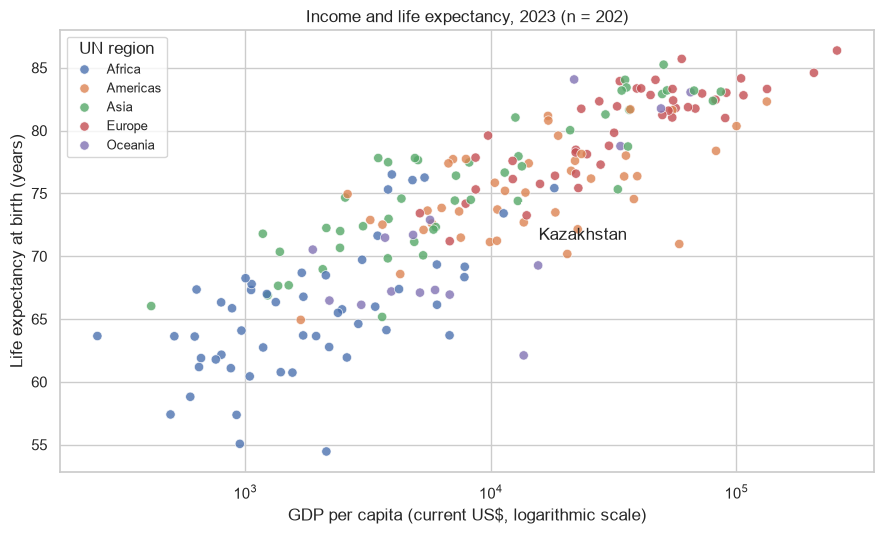

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=data, x='gdp_per_capita_usd', y='life_expectancy_years', hue='region',
                hue_order=sorted(data['region'].unique()), s=45, alpha=0.8, ax=ax)
ax.set_xscale('log')
ax.set(xlabel='GDP per capita (current US$, logarithmic scale)', ylabel='Life expectancy at birth (years)',
       title=f'Income and life expectancy, 2023 (n = {len(data)})')
kz = data.loc[data['iso3'].eq('KAZ')]
if not kz.empty:
    row = kz.iloc[0]
    ax.annotate('Kazakhstan', (row['gdp_per_capita_usd'], row['life_expectancy_years']),
                xytext=(15, -28), textcoords='offset points', arrowprops={'arrowstyle': '->'})
ax.legend(title='UN region', fontsize=9)
fig.tight_layout()
fig.savefig(FIG / '01_gdp_life_expectancy.png', dpi=180)
plt.show()

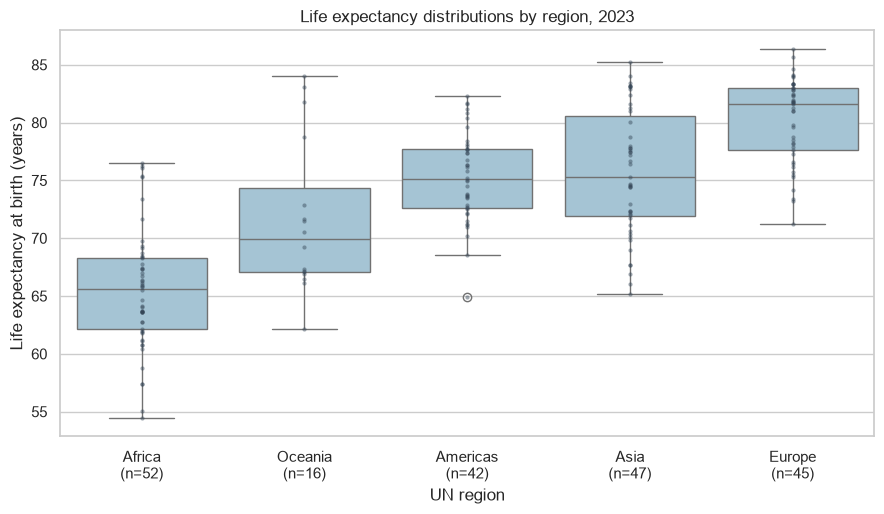

In [8]:
order = regional.index.tolist()
fig, ax = plt.subplots(figsize=(9, 5.3))
sns.boxplot(data=data, x='region', y='life_expectancy_years', order=order, color='#9dc6dc', ax=ax)
sns.stripplot(data=data, x='region', y='life_expectancy_years', order=order,
              color='#334455', size=3, alpha=0.45, jitter=False, ax=ax)
ax.set_xticks(range(len(order)), [f"{region}\n(n={int(regional.loc[region, 'n'])})" for region in order])
ax.set(xlabel='UN region', ylabel='Life expectancy at birth (years)',
       title='Life expectancy distributions by region, 2023')
fig.tight_layout()
fig.savefig(FIG / '02_life_by_region.png', dpi=180)
plt.show()

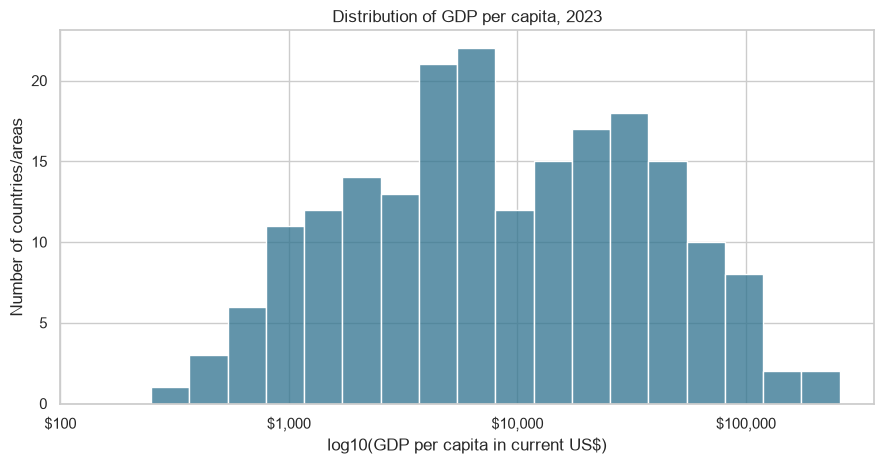

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(data=data, x='log10_gdp_per_capita', bins=18, color='#2d718e', ax=ax)
ax.set(xlabel='log10(GDP per capita in current US$)', ylabel='Number of countries/areas',
       title='Distribution of GDP per capita, 2023')
ax.set_xticks([2, 3, 4, 5], ['$100', '$1,000', '$10,000', '$100,000'])
fig.tight_layout()
fig.savefig(FIG / '03_gdp_distribution.png', dpi=180)
plt.show()

## 8. Coverage and sensitivity checks
Exclusions may be uneven across regions. The table uses matched World Bank countries/areas
as its denominator; unmatched rows are listed separately. The sensitivity calculation
removes the top 5% of GDP observations only as a check, without changing the main dataset.

In [10]:
coverage = merged.loc[merged['region'].notna()].groupby('region').agg(
    available=('iso3', 'size'), included=('included', 'sum'))
coverage['coverage_pct'] = 100 * coverage['included'] / coverage['available']
display(coverage.round(1))
coverage.to_csv(CLEAN / 'regional_coverage.csv')
cutoff = data['gdp_per_capita_usd'].quantile(0.95)
sensitivity = data.loc[data['gdp_per_capita_usd'] <= cutoff]
sensitivity_r = sensitivity['log10_gdp_per_capita'].corr(sensitivity['life_expectancy_years'])
print(f'Without the highest-GDP 5%: n={len(sensitivity)}, log-GDP Pearson r={sensitivity_r:.3f}')
display(kz.round(2))
metrics = {'year': YEAR, 'n': len(data), 'pearson_raw': pearson_raw, 'pearson_log': pearson_log,
           'spearman': spearman, 'sensitivity_n': len(sensitivity), 'sensitivity_r': sensitivity_r,
           'median_gdp': data['gdp_per_capita_usd'].median(),
           'median_life': data['life_expectancy_years'].median(),
           'kazakhstan': kz.to_dict('records'), 'audit': audit}
(CLEAN / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')

,available,included,coverage_pct
region,,,
Africa,54,52,96.3
Americas,46,42,91.3
Asia,50,47,94.0
Europe,46,45,97.8
Oceania,19,16,84.2


Without the highest-GDP 5%: n=191, log-GDP Pearson r=0.844


,iso3,country_wb,year,region,subregion,gdp_per_capita_usd,life_expectancy_years,log10_gdp_per_capita
99,KAZ,Kazakhstan,2023,Asia,Central Asia,12879.43,74.4,4.11


943

In [11]:
low, high = regional.iloc[0], regional.iloc[-1]
display(Markdown(f"""## 9. Findings and limitations

1. The final sample contains **{len(data)} countries/areas**. From {len(wide)} World Bank
   country/area rows, {len(excluded)} were excluded because of missing indicators or geographic matches.
2. GDP and life expectancy have a positive association: Pearson **r = {pearson_raw:.3f}**
   on the original GDP scale and **r = {pearson_log:.3f}** using log10 GDP. The rank correlation
   is **{spearman:.3f}**. The log scale describes this relationship more closely as a linear pattern.
3. Median life expectancy is **{high['median_life_years']:.1f} years** in {regional.index[-1]}
   and **{low['median_life_years']:.1f} years** in {regional.index[0]} in this sample.
   These summarize countries/areas equally, not individual people.
4. Sample medians are **US${metrics['median_gdp']:,.0f}** for GDP per capita and
   **{metrics['median_life']:.1f} years** for life expectancy.
5. Removing the highest-GDP 5% leaves a positive log-GDP correlation of
   **{sensitivity_r:.3f}** across {len(sensitivity)} observations.

This is descriptive cross-sectional analysis. Health care, education, inequality, conflict,
and other variables may affect both measures; correlation does not show that increasing
GDP alone would increase life expectancy. Missingness and unmatched territories can bias
the sample. Current-dollar GDP is not PPP-adjusted, and countries differ in statistical
quality. Future work could compare PPP GDP and several years using the same coverage rules.
"""))
display(pd.DataFrame.from_dict(manifest, orient='index')[['url', 'retrieved_qyzylorda', 'sha256']])

## 9. Findings and limitations

1. The final sample contains **202 countries/areas**. From 217 World Bank
   country/area rows, 15 were excluded because of missing indicators or geographic matches.
2. GDP and life expectancy have a positive association: Pearson **r = 0.620**
   on the original GDP scale and **r = 0.856** using log10 GDP. The rank correlation
   is **0.866**. The log scale describes this relationship more closely as a linear pattern.
3. Median life expectancy is **81.6 years** in Europe
   and **65.6 years** in Africa in this sample.
   These summarize countries/areas equally, not individual people.
4. Sample medians are **US$7,862** for GDP per capita and
   **74.5 years** for life expectancy.
5. Removing the highest-GDP 5% leaves a positive log-GDP correlation of
   **0.844** across 191 observations.

This is descriptive cross-sectional analysis. Health care, education, inequality, conflict,
and other variables may affect both measures; correlation does not show that increasing
GDP alone would increase life expectancy. Missingness and unmatched territories can bias
the sample. Current-dollar GDP is not PPP-adjusted, and countries differ in statistical
quality. Future work could compare PPP GDP and several years using the same coverage rules.


,url,retrieved_qyzylorda,sha256
countries_page1.json,https://api.worldbank.org/v2/country?format=js...,2026-10-12T20:47:30.567882+05:00,c9acf3932785191a649cbc04c3056af4cf64a236e5c3b4...
NY.GDP.PCAP.CD_page1.json,https://api.worldbank.org/v2/country/all/indic...,2026-10-12T20:48:03.460306+05:00,97bb3fed315ff8fa4b4390ff9d0e32262cba8d4b9bafb7...
SP.DYN.LE00.IN_page1.json,https://api.worldbank.org/v2/country/all/indic...,2026-10-12T20:48:28.502797+05:00,2c3a31d481a2f594ae78439e2b778fdf6c7b8d23ad29fc...
un_robots.txt,https://unstats.un.org/robots.txt,2026-10-12T20:48:30.243990+05:00,2bb8d8fab534b36e99b79b5b95e18b68cbdd582ceed24c...
un_m49.html,https://unstats.un.org/unsd/methodology/m49/ov...,2026-10-12T20:48:31.728081+05:00,b9048114f6e7f2abda83bf03d4263c9d7cd1bd7230e3d0...


## References
All sources accessed **12 October 2026**. Dates of observation (2023), API updates, and
access dates are different concepts; the request manifest preserves the exact access time.

1. World Bank. *GDP per capita (current US$), NY.GDP.PCAP.CD*. World Development Indicators.
   https://data.worldbank.org/indicator/NY.GDP.PCAP.CD
2. World Bank. *Life expectancy at birth, total (years), SP.DYN.LE00.IN*. World Development Indicators.
   https://data.worldbank.org/indicator/SP.DYN.LE00.IN
3. World Bank. *API Basic Call Structures*.
   https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures
4. United Nations Statistics Division. *Standard country or area codes for statistical use (M49)*.
   https://unstats.un.org/unsd/methodology/m49/overview/
5. United Nations Statistics Division. *robots.txt*.
   https://unstats.un.org/robots.txt

World Bank indicator pages identify the data license as CC BY 4.0. The UN page is credited
separately; the World Bank license is not assumed to cover UN content.